In [1]:
%matplotlib inline
#%matplotlib widget

import os
import re
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from dataclasses import dataclass
import inspect

@dataclass
class RamanSpectrum:
    filename: str
    folder: str
    df: pd.DataFrame          
    label: str = ""
    laser: str = "Unknown"
    grating: str = "Unknown"
    objective: str = "Unknown"
    var_name: str = ""
    color: str = "#000000"
    linestyle: str = "-"
    scale: float = 1.0        
    offset: float = 0.0       

    def __post_init__(self):
        # Regex field extraction
        if not self.label or self.label == self.filename:
            try:
                text = os.path.splitext(self.filename)[0]
                text = re.sub(r'^(Ren_|Xpl_|S_)', '', text)
                text = re.sub(r'^\d{6,8}_?', '', text)
                text = re.sub(r'_?(473|532|633|638|785)\s*_?nm.*$', '', text, flags=re.IGNORECASE)
                extracted = text.strip('_ ')
                self.label = extracted if extracted else self.filename
            except Exception:
                self.label = self.filename

        laser_match = re.search(r'(473|532|633|638|785)\s*nm', self.filename, re.IGNORECASE)
        if laser_match:
            self.laser = f"{laser_match.group(1)} nm"
        grating_match = re.search(r'(\d{3,4})\s*gr', self.filename, re.IGNORECASE)
        if grating_match:
            self.grating = f"{grating_match.group(1)} gr/mm"
        objective_match = re.search(r'x(\d+)(_LD| LD)?', self.filename, re.IGNORECASE)
        if objective_match:
            self.objective = f"x{objective_match.group(1)}{' LD' if objective_match.group(2) else ''}"

    def copy(self):
        return RamanSpectrum(
            filename=self.filename, folder=self.folder, df=self.df.copy(),
            label=self.label, laser=self.laser, grating=self.grating,
            objective=self.objective, var_name=self.var_name,
            color=self.color, linestyle=self.linestyle,
            scale=self.scale, offset=self.offset
        )

    @property
    def X(self): return self.df["RamanShift"].values

    @property
    def Y(self): return self.df["Intensity"].values

    @Y.setter
    def Y(self, new_y): self.df["Intensity"] = new_y

    def subtract(self, reference_spectrum):
        if not isinstance(reference_spectrum, RamanSpectrum):
            raise TypeError("Arg must be Raman Spec.")
        
        interpolated_Y = np.interp(self.X, reference_spectrum.X, reference_spectrum.Y, left=0.0, right=0.0)
        new_df = pd.DataFrame({"RamanShift": self.X, "Intensity": self.Y - interpolated_Y})
        
        return RamanSpectrum(
            filename=f"Sub_{self.filename}",
            folder="Calculated",
            df=new_df,
            label=f"{self.label} - {reference_spectrum.label}",
            laser=self.laser,
            grating=self.grating,
            objective=self.objective,
            color="#FF0000",
            linestyle="--"
        )

In [2]:
def TrimSpectrum(spec_obj, xmin=None, xmax=None):
    s = spec_obj.copy()
    mask = np.ones_like(s.X, dtype=bool)
    if xmin is not None: mask &= (s.X >= xmin)
    if xmax is not None: mask &= (s.X <= xmax)
    s.df = s.df[mask].copy().reset_index(drop=True)
    return s

def SubtractBaseline(spec_obj, poly_order=1, anchor_windows=None):
    s = spec_obj.copy()
    X, Y = s.X, s.Y
    if len(X) == 0: return s

    if poly_order == 0:
        s.Y = Y - np.min(Y)
        return s

    if anchor_windows is None:
        n_pts = max(3, int(len(X) * 0.05))
        mask = np.zeros_like(X, dtype=bool)
        mask[:n_pts] = True
        mask[-n_pts:] = True
    else:
        mask = np.zeros_like(X, dtype=bool)
        for wmin, wmax in anchor_windows:
            mask |= ((X >= wmin) & (X <= wmax))

    if np.sum(mask) > poly_order:
        coeffs = np.polyfit(X[mask], Y[mask], poly_order)
        s.Y = Y - np.polyval(coeffs, X)
    return s

def NormalizeSpectrum(spec_obj, xmin=None, xmax=None, mode="M", subtract_min_first=True):
    s = spec_obj.copy()
    if mode is None or mode.upper() == "NONE": return s

    X, Y = s.X, s.Y
    mask = np.ones_like(X, dtype=bool)
    if xmin is not None: mask &= (X >= xmin)
    if xmax is not None: mask &= (X <= xmax)

    X_win, Y_win = X[mask], Y[mask]
    if len(X_win) == 0: return s

    if subtract_min_first:
        min_val = np.min(Y_win)
        Y = Y - min_val
        Y_win = Y_win - min_val

    mode = mode.upper()
    if mode == "M": factor = np.max(Y_win)
    elif mode == "I": factor = np.trapezoid(Y_win, X_win)
    elif mode == "V": factor = np.min(Y_win)
    else: raise ValueError("Mode must be 'M', 'I', 'V', or 'NONE'")

    if factor != 0: s.Y = Y / factor
    return s


In [3]:

BASE_RENISHAW = r"H:\FUBerlin\Measurements\Raman Renishaw\CristianB"
BASE_XPLORA   = r"H:\FUBerlin\Measurements\Raman Xplora\CristianB"

def _resolve_target_paths(base_dir, sub_folders):
    if not sub_folders:  # Si pasas [] o None, no carga nada de ese equipo
        return []
    if not os.path.exists(base_dir):
        print(f"Base directory not found -> {base_dir}")
        return []
    if sub_folders == "ALL":
        return [base_dir]
    if isinstance(sub_folders, str):
        sub_folders = [sub_folders]

    target_paths = []
    all_items = [d for d in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, d))]

    for sf in sub_folders:
        exact_path = os.path.join(base_dir, sf)
        if os.path.isdir(exact_path):
            target_paths.append(exact_path)
        else:
            matches = [os.path.join(base_dir, d) for d in all_items if sf.lower() in d.lower()]
            if matches:
                target_paths.extend(matches)
            else:
                print(f"Subfolder not found in {base_dir}: '{sf}'")
    return list(dict.fromkeys(target_paths))

def _make_var_name(filename, prefix="S_"):
    base = os.path.splitext(filename)[0].replace("%", "pc").replace("@", "_in_")
    clean = re.sub(r'\W+', '_', base).strip('_')
    return f"{prefix}{clean}"

def _purge_globals(prefix):
    """Limpia variables globales viejas con el mismo prefijo para ahorrar RAM."""
    for key in list(globals().keys()):
        if key.startswith(prefix):
            del globals()[key]
    gc.collect()

def LoadRamanData_Renishaw(base_dir=BASE_RENISHAW, sub_folders="ALL", inject_globals=True, prefix="Ren_"):
    if inject_globals:
        _purge_globals(prefix)
    spectra_dict = {}
    for t_path in _resolve_target_paths(base_dir, sub_folders):
        for root, _, files in os.walk(t_path):
            folder_name = os.path.basename(root)
            for file in sorted(files):
                if not file.lower().endswith(".txt"): continue
                try:
                    df = pd.read_csv(os.path.join(root, file), sep=r'\s+', header=None, engine='python')
                    df = df.iloc[:, [0, 1]]
                    df.columns = ["RamanShift", "Intensity"]
                    df["RamanShift"] = pd.to_numeric(df["RamanShift"], errors="coerce")
                    df["Intensity"]  = pd.to_numeric(df["Intensity"], errors="coerce")
                    df = df.dropna().sort_values("RamanShift").reset_index(drop=True)

                    if len(df) > 0:
                        vname = _make_var_name(file, prefix=prefix)
                        spec = RamanSpectrum(filename=file, folder=folder_name, df=df, label=file, var_name=vname)
                        spectra_dict[vname] = spec
                        if inject_globals:
                            globals()[vname] = spec
                except Exception:
                    pass
    print(f"✅ Renishaw: Loaded {len(spectra_dict)} spectra.")
    return spectra_dict

def LoadRamanData_XploRA(base_dir=BASE_XPLORA, sub_folders="ALL", inject_globals=True, prefix="Xpl_"):
    if inject_globals:
        _purge_globals(prefix)
    spectra_dict = {}
    for t_path in _resolve_target_paths(base_dir, sub_folders):
        for root, _, files in os.walk(t_path):
            folder_name = os.path.basename(root)
            for file in sorted(files):
                if not file.lower().endswith(".txt"): continue
                try:
                    df = pd.read_csv(os.path.join(root, file), sep="\t", comment="#", header=None, encoding="latin1", usecols=[0, 1])
                    df.columns = ["RamanShift", "Intensity"]
                    df["RamanShift"] = pd.to_numeric(df["RamanShift"], errors="coerce")
                    df["Intensity"]  = pd.to_numeric(df["Intensity"], errors="coerce")
                    df = df.dropna().sort_values("RamanShift").reset_index(drop=True)

                    if len(df) > 0:
                        vname = _make_var_name(file, prefix=prefix)
                        spec = RamanSpectrum(filename=file, folder=folder_name, df=df, label=file, var_name=vname)
                        spectra_dict[vname] = spec
                        if inject_globals:
                            globals()[vname] = spec
                except Exception:
                    pass
    print(f"✅ XploRA: Loaded {len(spectra_dict)} spectra.")
    return spectra_dict

def PrintCatalog(spectra_dict):
    if not spectra_dict: return
    print("\n" + "="*80)
    print("Folder\tLaser\tGrating\tObjective\tVar_Name\tFilename_for_Config")
    for obj in sorted(spectra_dict.values(), key=lambda x: (x.folder, x.laser, x.filename)):
        print(f"{obj.folder}\t{obj.laser}\t{obj.grating}\t{obj.objective}\t{obj.var_name}\t'{obj.filename}'")
    print("="*80)

def AssignMetadata(spectra_dict, filename_pattern, laser=None, grating=None, objective=None, sample_label=None):
    count = 0
    for fname, spec in spectra_dict.items():
        if filename_pattern.lower() in fname.lower():
            if laser: spec.laser = laser
            if grating: spec.grating = grating
            if objective: spec.objective = objective
            if sample_label: spec.label = sample_label
            count += 1
    print(f"Updated metadata for {count} spectra matching '{filename_pattern}'.")

def FilterSpectra(spectra_dict, laser=None, grating=None, keyword=None):
    filtered = {}
    for fname, spec in spectra_dict.items():
        match_laser = (laser is None) or (spec.laser == laser)
        match_grating = (grating is None) or (spec.grating == grating)
        match_keyword = (keyword is None) or (keyword.lower() in fname.lower())
        if match_laser and match_grating and match_keyword:
            filtered[fname] = spec
    print(f"Found {len(filtered)} spectra matching criteria.")
    return filtered

In [4]:
renishaw_folders = [
]

xplora_folders = [
]

raman_spectra_renishaw = LoadRamanData_Renishaw(BASE_RENISHAW)
raman_spectra_xplora   = LoadRamanData_XploRA(BASE_XPLORA)

raman_spectra = raman_spectra_renishaw | raman_spectra_xplora
PrintCatalog(raman_spectra)

✅ Renishaw: Loaded 9 spectra.
✅ XploRA: Loaded 213 spectra.

Folder	Laser	Grating	Objective	Var_Name	Filename_for_Config
473nm	473 nm	Unknown	Unknown	Ren_F006WA_phDADQ_473nm	'F006WA_phDADQ_473nm.txt'
473nm	473 nm	Unknown	Unknown	Ren_P2Ref_473nm	'P2Ref_473nm.txt'
532nm	532 nm	1800 gr/mm	x10	Xpl_260529_6FBz_532_nm_1800gr_x10_1pc_3_120_50_100	'260529_6FBz_532 nm_1800gr_x10_1%_3_120_50_100.txt'
532nm	532 nm	1800 gr/mm	x10	Xpl_260529_F005AP_6FBz_in_P2Sol_532_nm_1800gr_x10_1pc_3_120_50_100	'260529_F005AP_6FBz@P2Sol_532 nm_1800gr_x10_1%_3_120_50_100.txt'
532nm	532 nm	1800 gr/mm	x10	Xpl_260529_F005LP_6FBz_in_P2Sol_532_nm_1800gr_x10_1pc_3_120_50_100	'260529_F005LP_6FBz@P2Sol_532 nm_1800gr_x10_1%_3_120_50_100.txt'
532nm	532 nm	1800 gr/mm	x10	Xpl_260529_P2ReferenceSol_532_nm_1800gr_x10_1pc_3_120_50_100	'260529_P2ReferenceSol_532 nm_1800gr_x10_1%_3_120_50_100.txt'
532nm	532 nm	600 gr/mm	x10	Xpl_260605_6FBz_532_nm_600gr_x10_1pc_3_10_50_100_sc2700	'260605_6FBz_532 nm_600gr_x10_1%_3_10_50_100_sc2700.

In [5]:
BASE_OUTPUT = r"H:\FUBerlin\PhD_CristianBorja\Results Overview\Push-pull (phDADQ)\Figures\Raman"

poster_style = {
    "figsize": (4, 3),
    "dpi": 300,
    "font_size": 10,
    "title_size": 11,
    "label_size": 11,
    "legend_size": 8,
    "line_width": 1.0,
    "font_family": "Calibri",
    "grid": False,
    "colors": ["#000000", "#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9"],
    "linestyles": ["-", "--", "-.", ":"]
}


def _find_var_name(obj, caller_frame):
    """Finds the variable name of `obj` in the caller's scope."""
    for scope in (caller_frame.f_locals, caller_frame.f_globals):
        for name, val in scope.items():
            if val is obj and not name.startswith("_"):
                return name
    return None

def PlotRamanConfig(
    config, spectra_dict=None, style=poster_style, offset_step=0.0,
    xmin=None, xmax=None, ymin=None, ymax=None,
    norm_xmin=None, norm_xmax=None, norm_mode="M", subtract_min_first=True,
    vlines=None, hide_yticks=True, legend_ncol=1,
    title=None, save=False, save_dir=BASE_OUTPUT, save_formats=("svg",)
):
    plt.close('all')
    fig, ax = plt.subplots(figsize=style["figsize"], dpi=style["dpi"])
    plt.rcParams.update({"font.size": style["font_size"], "font.family": style["font_family"]})

    for i, item in enumerate(config):
        source, label, color, ls = item[0], item[1], item[2], item[3]
        manual_scale = item[4] if len(item) > 4 else 1.0
        ind_trim = item[5] if len(item) > 5 else None

        if isinstance(source, RamanSpectrum):
            s = source.copy()
        elif isinstance(source, str) and spectra_dict and source in spectra_dict:
            s = spectra_dict[source].copy()
        else:
            print(f"⚠️ Spectrum not found: {source}")
            continue

        if norm_mode and norm_mode.upper() != "NONE":
            s = NormalizeSpectrum(s, xmin=norm_xmin, xmax=norm_xmax, mode=norm_mode, subtract_min_first=subtract_min_first)

        if xmin is not None or xmax is not None:
            s = TrimSpectrum(s, xmin=xmin, xmax=xmax)

        if ind_trim is not None:
            s = TrimSpectrum(s, xmin=ind_trim[0], xmax=ind_trim[1])

        s.Y = (s.Y * manual_scale) + (i * offset_step)
        ax.plot(s.X, s.Y, label=label, color=color, linestyle=ls, linewidth=style["line_width"])
        ###ax.scatter(s.X, s.Y, color=color, s=0.1)

    ax.set_xlabel("Raman shift (cm$^{-1}$)", fontsize=style["label_size"])
    ax.set_ylabel("Intensity (a.u.)", fontsize=style["label_size"])

    if xmin is not None or xmax is not None: ax.set_xlim(xmin, xmax)
    if ymin is not None or ymax is not None: ax.set_ylim(ymin, ymax)
    if style.get("grid", False): ax.grid(True, alpha=0.3)
    if hide_yticks:
        ax.set_yticklabels([])
        ax.set_yticks([])

    if vlines is not None:
        for x_val in vlines:
            ax.axvline(x=x_val, linewidth=0.7, linestyle='--', color='#555555', alpha=0.8, zorder=0)

    if title: ax.set_title(title, fontsize=style["title_size"])
    ax.legend(fontsize=style["legend_size"], ncol=legend_ncol, frameon=False)
    plt.tight_layout()

    if save:
        if isinstance(save, str):
            base_name = os.path.splitext(save)[0]
        else:
            # Auto-detect the variable name passed to `config`
            caller_frame = inspect.currentframe().f_back
            base_name = _find_var_name(config, caller_frame) or "Raman_Plot"

        os.makedirs(save_dir, exist_ok=True)
        formats = [save_formats] if isinstance(save_formats, str) else save_formats
        for ext in formats:
            full_path = os.path.join(save_dir, f"{base_name}.{ext.lstrip('.')}")
            plt.savefig(full_path, dpi=style["dpi"], bbox_inches="tight")
            print(f"💾 Saved: {full_path}")
            
    plt.show()



def _matches_where(searchable, where):
    """Evalúa expresiones tipo '532 AND (phDADQ OR P2Ref) AND NOT 600gr'."""
    if where is None:
        return True
    if isinstance(where, (list, tuple)):
        return all(str(t).lower() in searchable for t in where)

    tokens = re.findall(r'\(|\)|\bAND\b|\bOR\b|\bNOT\b|"[^"]+"|\'[^\']+\'|[^\s()]+', where, flags=re.IGNORECASE)
    expr = []
    for tok in tokens:
        up = tok.upper()
        if up in ("(", ")", "AND", "OR", "NOT"):
            expr.append(up.lower())
        else:
            term = tok.strip('"\'').lower()
            expr.append(str(term in searchable))
    try:
        return bool(eval(" ".join(expr), {"__builtins__": None}, {}))
    except Exception:
        raise ValueError(f"Expresión 'where' inválida: {where}")
    

def MakeConfig(specs, where=None, style=poster_style):
    """
    Filtra espectros usando búsqueda textual con AND, OR, NOT y paréntesis,
    e imprime el bloque config listo para copiar usando sp.label.
    """
    items = list(specs.values()) if isinstance(specs, dict) else list(specs)

    if where is not None:
        filtered = []
        for sp in items:
            searchable = f"{sp.var_name} {sp.filename} {sp.folder} {sp.laser} {sp.grating} {sp.objective} {sp.label}".lower()
            if _matches_where(searchable, where):
                filtered.append(sp)
        items = filtered

    if not items:
        print(f"No spectra found matching where={where}")
        return

    colors = style.get("colors", ["#000000", "#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9"])
    print(f"# Found {len(items)} spectra (where={where})")
    print("config = [")
    for i, sp in enumerate(items):
        vname = sp.var_name if isinstance(sp, RamanSpectrum) else str(sp)
        label = sp.label if isinstance(sp, RamanSpectrum) else str(sp)
        col = colors[i % len(colors)]
        print(f"    ({vname}, '{label}', '{col}', '-'),")
    print("]")

In [6]:
for i in list(raman_spectra.keys()):
    print(i + ',')

Ren_F006WA_phDADQ_473nm,
Ren_P2Ref_473nm,
Ren_BluephDADQ,
Ren_BluephDADQ1,
Ren_NewMesd,
Ren_P2,
Ren_P21,
Ren_iughuio,
Ren_sumary_Copy,
Xpl_NoPoTS_G2D_532_nm_1200gr_x10_5_5_s_1pc,
Xpl_NoPoTS_RBMG_532_nm_1200gr_x10_5_5_s_1pc,
Xpl_NoPoTS_RBM_532_nm_2400gr_x10_5_5_s_10pc,
Xpl_P2TS_G2D_532_nm_1200gr_x10_5_5_s_1pc,
Xpl_P2TS_RBMG_532_nm_1200gr_x10_5_5_s_1pc,
Xpl_P2TS_RBM_532_nm_1800gr_x10_5_5_s_10pc,
Xpl_P2TS_RBM_532_nm_2400gr_x10_5_5_s_10pc,
Xpl_NoPoTS_G2D_638_nm_1200gr_x10_5_5_s_10pc,
Xpl_NoPoTS_RBMG_638_nm_1200gr_x10_2_60_s_0_1pc,
Xpl_NoPoTS_RBM_638_nm_1800gr_x10_5_5_s_100pc,
Xpl_P2TS_G2D_638_nm_1200gr_x10_5_5_s_10pc_1,
Xpl_P2TS_RBMG_638_nm_1200gr_x10_5_5_s_10pc_2,
Xpl_P2TS_RBM_638_nm_1800gr_x10_5_5_s_100pc,
Xpl_P2TS_2D_785_nm_1200gr_x10_5_5_s_10pc,
Xpl_P2TS_G_785_nm_1200gr_x10_5_5_s_10pc,
Xpl_P2TS_RBM_785_nm_1800gr_x10_5_5_s_100pc,
Xpl_NanIn_BS_RBM___532_nm_2400gr_x10_2_120_s_1pc,
Xpl_NanIn_TS_RBM___532_nm_2400gr_x10_2_120_s_1pc_1,
Xpl_NoPo_TS_RBM___532_nm_2400gr_x10_2_120_s_1pc,
Xpl_P2_T

In [ ]:
if 1==0:
    poster_style = {
        "figsize": (4, 3),
        "dpi": 300,
        "font_size": 10,
        "title_size": 11,
        "label_size": 11,
        "legend_size": 8,
        "line_width": 1.0,
        "font_family": "Calibri",
        "grid": False,
        "colors": ["#000000", "#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9"],
        "linestyles": ["-", "--", "-.", ":"]
    }


## 473nm Data

In [25]:
MakeConfig(raman_spectra, where="(F006 OR phDADQ OR P2) AND (473nm)")

# Found 2 spectra (where=(F006 OR phDADQ OR P2) AND (473nm))
config = [
    (Ren_F006WA_phDADQ_473nm, 'F006WA_phDADQ', '#000000', '-'),
    (Ren_P2Ref_473nm, 'P2Ref', '#0072B2', '-'),
]


💾 Saved: H:\FUBerlin\PhD_CristianBorja\Results Overview\Push-pull (phDADQ)\Figures\Raman\Data473nm2400gr261116.svg


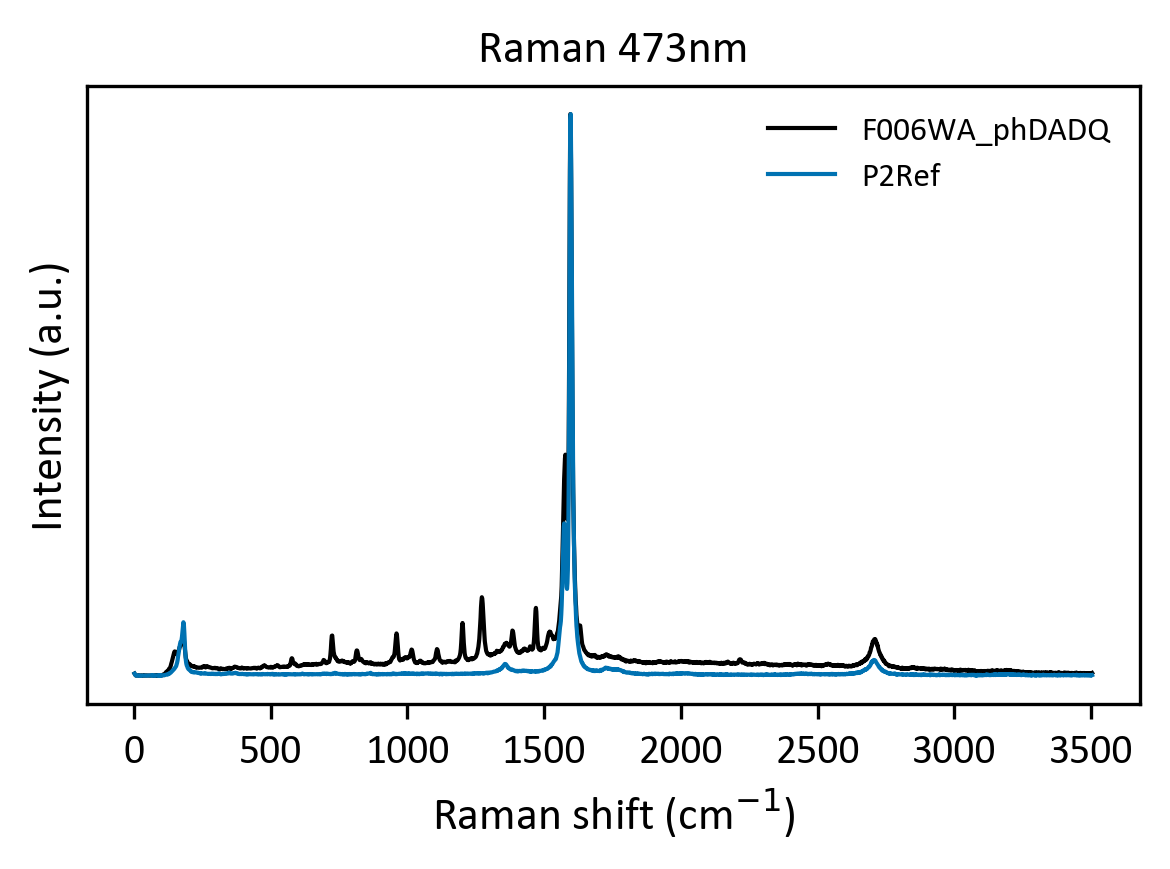

In [26]:
Data473nm2400gr261116 = [
    (Ren_F006WA_phDADQ_473nm, 'F006WA_phDADQ', '#000000', '-'),
    (Ren_P2Ref_473nm, 'P2Ref', '#0072B2', '-'),
]

PlotRamanConfig(
    style=poster_style,
    config=Data473nm2400gr261116, 
    spectra_dict=raman_spectra, 
    offset_step=0.0,
    #xmin=None, xmax=None, 
    #ymin=None, ymax=None,
    #norm_xmin=None, norm_xmax=None, norm_mode="M", 
    #subtract_min_first=True,
    #vlines=None, 
    hide_yticks=True, 
    legend_ncol=1,
    title="Raman 473nm", 
    save=True)

## 532nm Data

In [7]:
MakeConfig(raman_spectra, where="(F006 OR phDADQ OR P2) AND (532) AND (600gr)")

# Found 15 spectra (where=(F006 OR phDADQ OR P2) AND (532) AND (600gr))
config = [
    (Xpl_260605_F005AP_6FBz_in_P2Sol_CF260528_532_nm_600gr_x10_1pc_3_10_50_100_sc2700, 'F005AP_6FBz@P2Sol_CF260528', '#000000', '-'),
    (Xpl_260605_F005LP_6FBz_in_P2Sol_CF260528_532_nm_600gr_x10_1pc_3_10_50_100_sc2700, 'F005LP_6FBz@P2Sol_CF260528', '#0072B2', '-'),
    (Xpl_260605_F006WA_phDADQ_in_P2Sol_CF260605_532_nm_600gr_x10_1pc_3_10_50_100_sc2700, 'F006WA_phDADQ@P2Sol_CF260605', '#E69F00', '-'),
    (Xpl_260605_P2_RefSol_NS_CF260529_532_nm_600gr_x10_1pc_3_10_50_100_sc2700, 'P2_RefSol_NS_CF260529', '#009E73', '-'),
    (Xpl_260605_P2_RefSol_TSR2_CF260224_532_nm_600gr_x10_1pc_3_10_50_100_sc2700, 'P2_RefSol_TSR2_CF260224', '#CC79A7', '-'),
    (Xpl_260909_Cl2_in_P2_A_532_nm_600gr_x50_LD_1pc_5_5_100_300_sc2660, 'Cl2@P2_A', '#D55E00', '-'),
    (Xpl_260909_Cl2_in_P2_B_532_nm_600gr_x50_LD_1pc_5_5_100_300_sc2660, 'Cl2@P2_B', '#56B4E9', '-'),
    (Xpl_260909_P2_532_nm_600gr_x50_LD_1pc_5_5_100_300_sc2660, 

💾 Saved: H:\FUBerlin\PhD_CristianBorja\Results Overview\Push-pull (phDADQ)\Figures\Raman\Data532nm600gr260605.svg


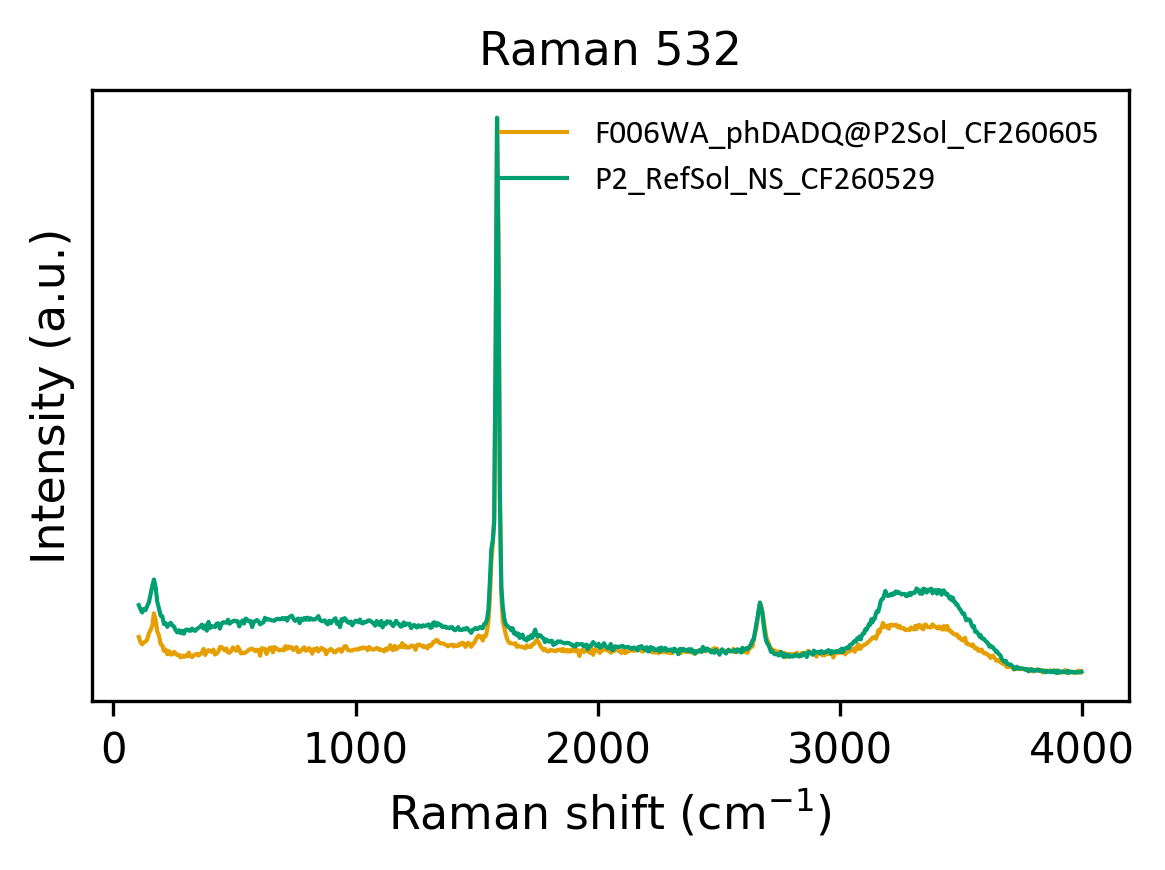

In [9]:
Data532nm600gr260605 = [
    (Xpl_260605_F006WA_phDADQ_in_P2Sol_CF260605_532_nm_600gr_x10_1pc_3_10_50_100_sc2700, 'F006WA_phDADQ@P2Sol_CF260605', '#E69F00', '-'),
    (Xpl_260605_P2_RefSol_NS_CF260529_532_nm_600gr_x10_1pc_3_10_50_100_sc2700, 'P2_RefSol_NS_CF260529', '#009E73', '-'),
    ##(Xpl_260605_P2_RefSol_TSR2_CF260224_532_nm_600gr_x10_1pc_3_10_50_100_sc2700, 'P2_RefSol_TSR2_CF260224', '#CC79A7', '-'),
]

PlotRamanConfig(
    style=poster_style,
    config=Data532nm600gr260605, 
    spectra_dict=raman_spectra, 
    offset_step=0.0,
    #xmin=None, xmax=None, 
    #ymin=None, ymax=None,
    #norm_xmin=None, norm_xmax=None, norm_mode="M", 
    #subtract_min_first=True,
    #vlines=None, 
    hide_yticks=True, 
    legend_ncol=1,
    title="Raman 532", 
    save=True)

💾 Saved: H:\FUBerlin\PhD_CristianBorja\Results Overview\Push-pull (phDADQ)\Figures\Raman\Data532nm600gr261114.svg


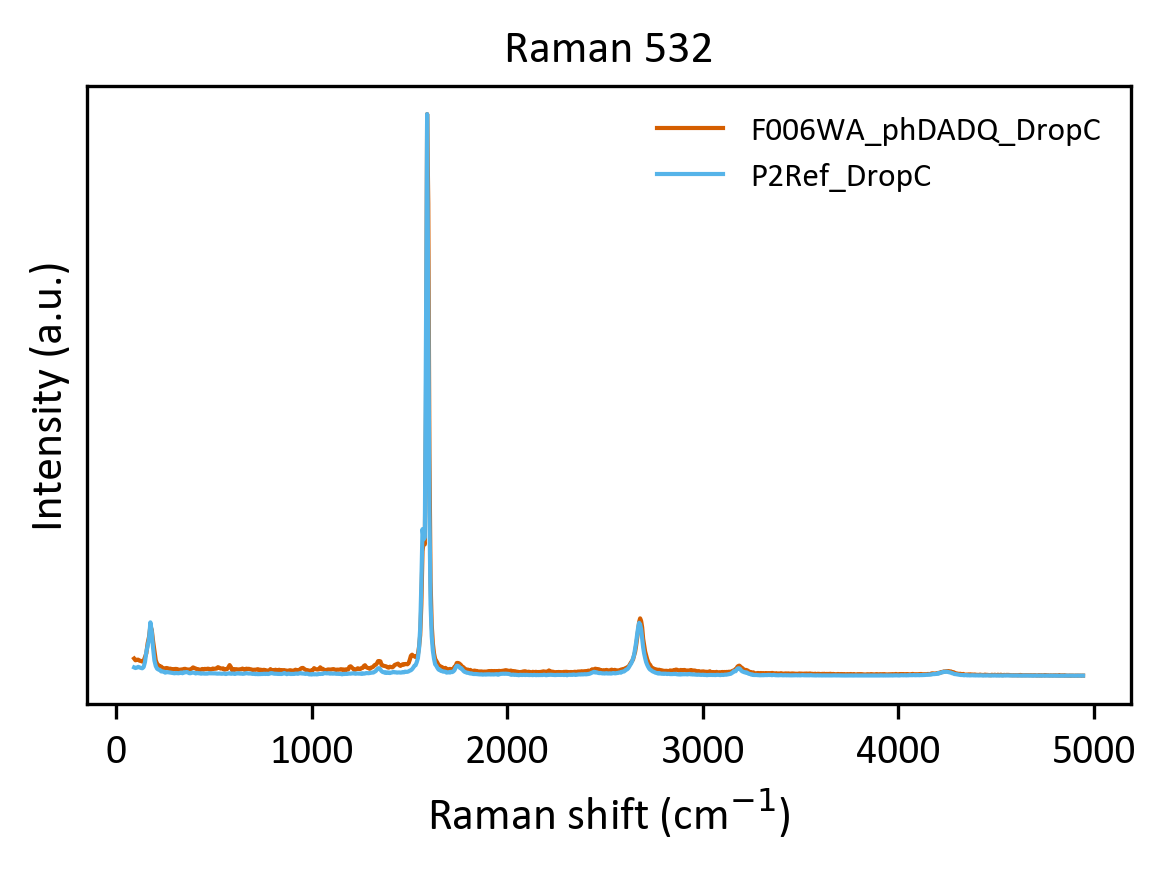

In [10]:
Data532nm600gr261114 = [
    (Xpl_261114_F006WA_phDADQ_DropC_532_nm_600gr_x50_LD_0_1pc_3_10_50_500_sc2700, 'F006WA_phDADQ_DropC', '#D55E00', '-'),
    (Xpl_261114_P2Ref_DropC_532_nm_600gr_x50_LD_0_1pc_3_10_50_500_sc2700, 'P2Ref_DropC', '#56B4E9', '-'),
    #(Xpl_261114_phDADQ_532_nm_600gr_x50_1pc_3_40_50_100_sc2700, 'phDADQ', '#000000', '-'),
]

PlotRamanConfig(
    style=poster_style,
    config=Data532nm600gr261114, 
    spectra_dict=raman_spectra, 
    offset_step=0.0,
    #xmin=None, xmax=None, 
    #ymin=None, ymax=None,
    #norm_xmin=None, norm_xmax=None, norm_mode="M", 
    #subtract_min_first=True,
    #vlines=None, 
    hide_yticks=True, 
    legend_ncol=1,
    title="Raman 532", 
    save=True)

In [11]:
MakeConfig(raman_spectra, where="(F006 OR phDADQ OR P2) AND (532) AND (1200gr)")

# Found 20 spectra (where=(F006 OR phDADQ OR P2) AND (532) AND (1200gr))
config = [
    (Xpl_P2TS_G2D_532_nm_1200gr_x10_5_5_s_1pc, 'P2TS_G2D', '#000000', '-'),
    (Xpl_P2TS_RBMG_532_nm_1200gr_x10_5_5_s_1pc, 'P2TS_RBMG', '#0072B2', '-'),
    (Xpl_260807_F007_1BrC18_in_P2_CF_DCG_532_nm_1200gr_x10_0_1pc_3_30_50_100_sc1350, 'F007_1BrC18@P2_CF_DCG', '#E69F00', '-'),
    (Xpl_260807_P2_CF_DCG_532_nm_1200gr_x10_0_1pc_3_30_50_100_sc1350, 'P2_CF_DCG', '#009E73', '-'),
    (Xpl_260818_F005LP_6FBz_in_P2_CFDrop_532_nm_1200gr_x50_LD_0_1pc_3_20_100_300_sc1350, 'F005LP_6FBz@P2_CFDrop', '#CC79A7', '-'),
    (Xpl_260818_F006WA_phDADQ_in_P2_CFDrop_532_nm_1200gr_x50_LD_0_1pc_3_20_100_300_sc1350, 'F006WA_phDADQ@P2_CFDrop', '#D55E00', '-'),
    (Xpl_260818_F007WA_1BrC18_in_P2_CFDrop_532_nm_1200gr_x50_LD_0_1pc_3_20_100_300_sc1350, 'F007WA_1BrC18@P2_CFDrop', '#56B4E9', '-'),
    (Xpl_260818_P2_CFDrop_532_nm_1200gr_x50_LD_0_1pc_3_20_100_300_sc1350, 'P2_CFDrop', '#000000', '-'),
    (Xpl_260909_Cl2_in_P2_532_

💾 Saved: H:\FUBerlin\PhD_CristianBorja\Results Overview\Push-pull (phDADQ)\Figures\Raman\Data532nm1200gr260818.svg


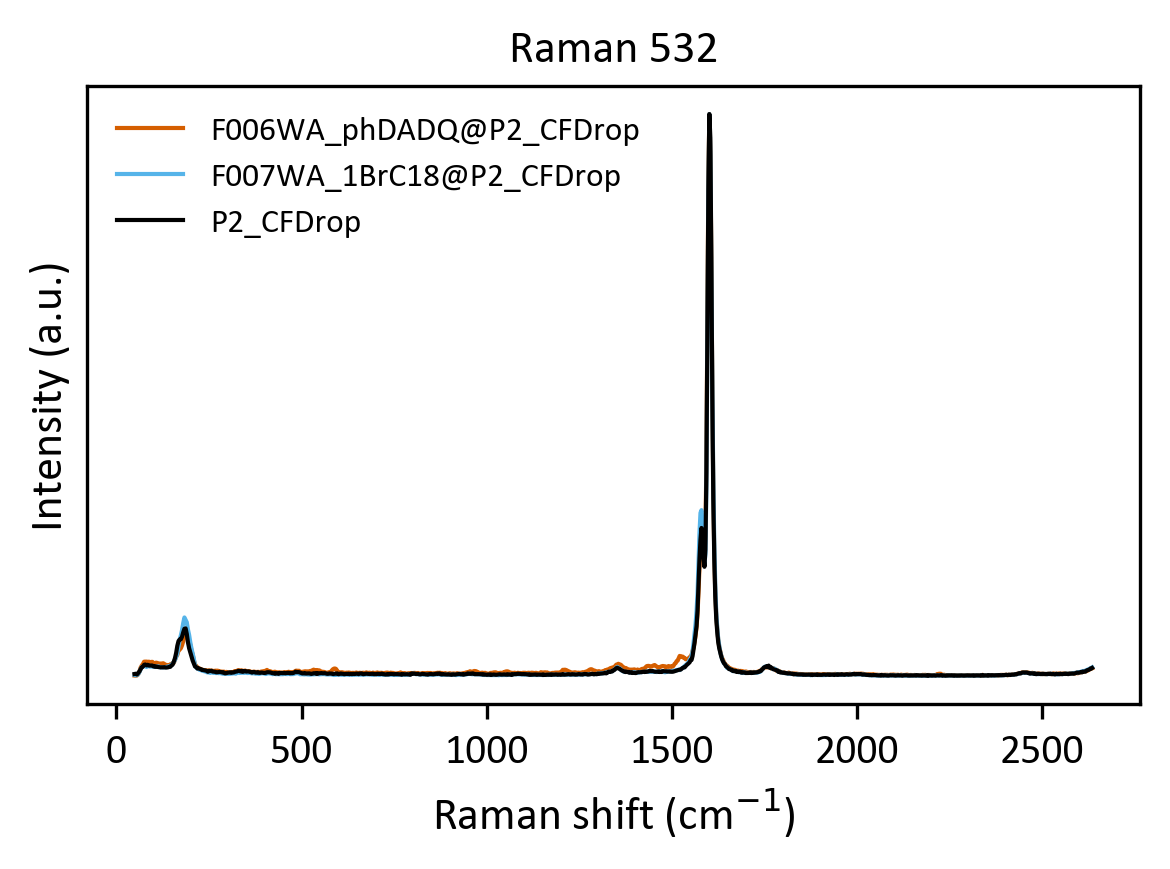

In [12]:
Data532nm1200gr260818 = [
    (Xpl_260818_F006WA_phDADQ_in_P2_CFDrop_532_nm_1200gr_x50_LD_0_1pc_3_20_100_300_sc1350, 'F006WA_phDADQ@P2_CFDrop', '#D55E00', '-'),
    (Xpl_260818_F007WA_1BrC18_in_P2_CFDrop_532_nm_1200gr_x50_LD_0_1pc_3_20_100_300_sc1350, 'F007WA_1BrC18@P2_CFDrop', '#56B4E9', '-'),
    (Xpl_260818_P2_CFDrop_532_nm_1200gr_x50_LD_0_1pc_3_20_100_300_sc1350, 'P2_CFDrop', '#000000', '-'),
]

PlotRamanConfig(
    style=poster_style,
    config=Data532nm1200gr260818, 
    spectra_dict=raman_spectra, 
    offset_step=0.0,
    #xmin=None, xmax=None, 
    #ymin=None, ymax=None,
    #norm_xmin=None, norm_xmax=None, norm_mode="M", 
    #subtract_min_first=True,
    #vlines=None, 
    hide_yticks=True, 
    legend_ncol=1,
    title="Raman 532", 
    save=True)

💾 Saved: H:\FUBerlin\PhD_CristianBorja\Results Overview\Push-pull (phDADQ)\Figures\Raman\Data532nm1200gr261114.svg


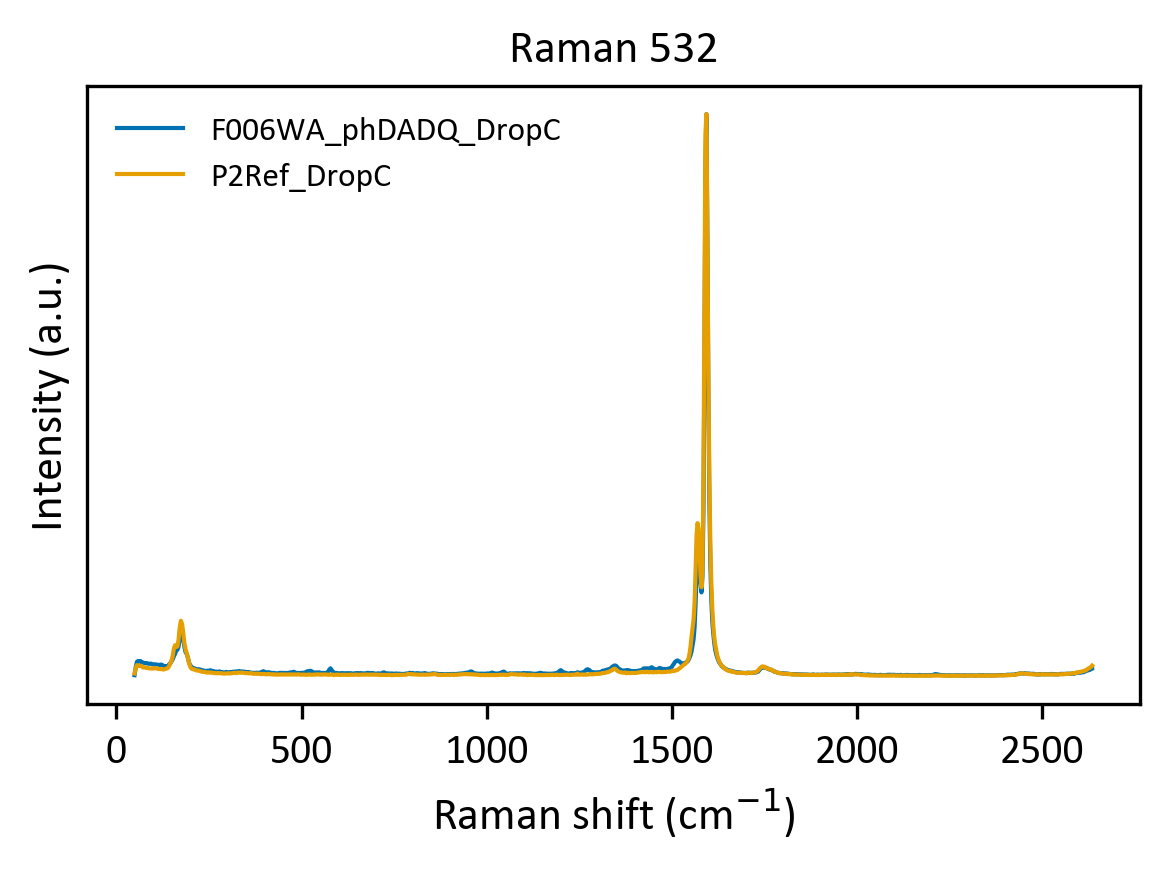

In [13]:
Data532nm1200gr261114 = [
    (Xpl_261114_F006WA_phDADQ_DropC_532_nm_1200gr_x50_0_1pc_3_90_50_100_sc1350, 'F006WA_phDADQ_DropC', '#0072B2', '-'),
    (Xpl_261114_P2Ref_DropC_532_nm_1200gr_x50_0_1pc_3_90_50_100_sc1350, 'P2Ref_DropC', '#E69F00', '-'),
    #(Xpl_261114_phDADQ_532_nm_1200gr_x50_1pc_2_120_50_100_sc1350, 'phDADQ or SiSO2', '#009E73', '-'),
    #(Xpl_261114_phDADQ_532_nm_1200gr_x50_1pc_3_40_50_100_sc1350, 'phDADQ or SiSO2', '#CC79A7', '-'),
    #(Xpl_261114_phDADQonSiWaf_532_nm_1200gr_x50_LD_1pc_5_1_50_100_sc1350, 'phDADQonSiWaf', '#D55E00', '-'),
]

PlotRamanConfig(
    style=poster_style,
    config=Data532nm1200gr261114, 
    spectra_dict=raman_spectra, 
    offset_step=0.0,
    #xmin=None, xmax=None, 
    #ymin=None, ymax=None,
    #norm_xmin=None, norm_xmax=None, norm_mode="M", 
    #subtract_min_first=True,
    #vlines=None, 
    hide_yticks=True, 
    legend_ncol=1,
    title="Raman 532", 
    save=True)

In [14]:
MakeConfig(raman_spectra, where="(F006 OR phDADQ OR P2) AND (532) AND (1800gr)")

# Found 17 spectra (where=(F006 OR phDADQ OR P2) AND (532) AND (1800gr))
config = [
    (Xpl_P2TS_RBM_532_nm_1800gr_x10_5_5_s_10pc, 'P2TS_RBM', '#000000', '-'),
    (Xpl_260529_F005AP_6FBz_in_P2Sol_532_nm_1800gr_x10_1pc_3_120_50_100, 'F005AP_6FBz@P2Sol', '#0072B2', '-'),
    (Xpl_260529_F005LP_6FBz_in_P2Sol_532_nm_1800gr_x10_1pc_3_120_50_100, 'F005LP_6FBz@P2Sol', '#E69F00', '-'),
    (Xpl_260529_P2ReferenceSol_532_nm_1800gr_x10_1pc_3_120_50_100, 'P2ReferenceSol', '#009E73', '-'),
    (Xpl_260818_F005LP_6FBz_in_P2_CFDrop_532_nm_1800gr_x50_LD_0_1pc_3_20_100_300_sc2150, 'F005LP_6FBz@P2_CFDrop', '#CC79A7', '-'),
    (Xpl_260818_F005LP_6FBz_in_P2_CFDrop_532_nm_1800gr_x50_LD_0_1pc_3_20_100_300_sc875, 'F005LP_6FBz@P2_CFDrop', '#D55E00', '-'),
    (Xpl_260818_F006WA_phDADQ_in_P2_CFDrop_532_nm_1800gr_x50_LD_0_1pc_3_20_100_300_sc2150, 'F006WA_phDADQ@P2_CFDrop', '#56B4E9', '-'),
    (Xpl_260818_F006WA_phDADQ_in_P2_CFDrop_532_nm_1800gr_x50_LD_0_1pc_3_20_100_300_sc875, 'F006WA_phDADQ@P2_CFDrop', '#

💾 Saved: H:\FUBerlin\PhD_CristianBorja\Results Overview\Push-pull (phDADQ)\Figures\Raman\Data532nm1800gr260818A.svg


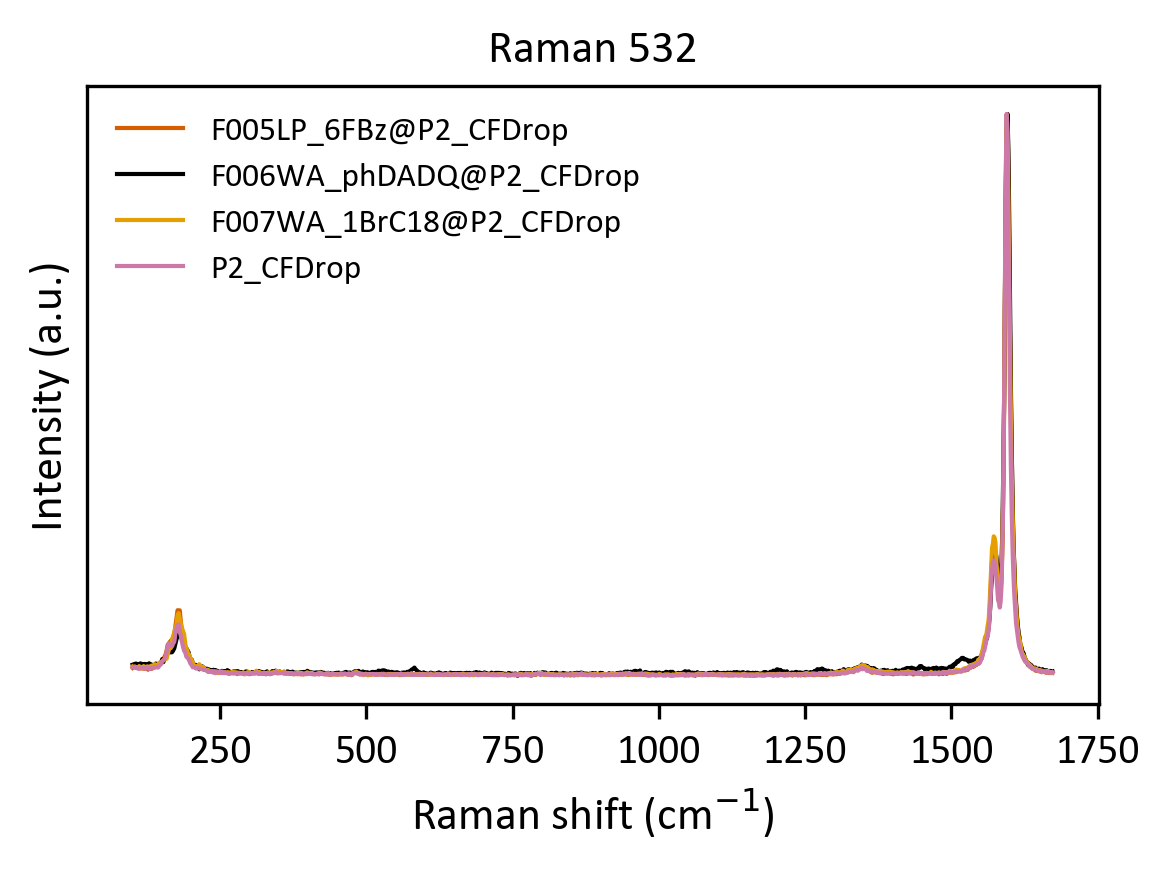

In [15]:
Data532nm1800gr260818A = [
    (Xpl_260818_F005LP_6FBz_in_P2_CFDrop_532_nm_1800gr_x50_LD_0_1pc_3_20_100_300_sc875, 'F005LP_6FBz@P2_CFDrop', '#D55E00', '-'),
    (Xpl_260818_F006WA_phDADQ_in_P2_CFDrop_532_nm_1800gr_x50_LD_0_1pc_3_20_100_300_sc875, 'F006WA_phDADQ@P2_CFDrop', '#000000', '-'),
    (Xpl_260818_F007WA_1BrC18_in_P2_CFDrop_532_nm_1800gr_x50_LD_0_1pc_3_20_100_300_sc875, 'F007WA_1BrC18@P2_CFDrop', '#E69F00', '-'),
    (Xpl_260818_P2_CFDrop_532_nm_1800gr_x50_LD_0_1pc_3_20_100_300_sc875, 'P2_CFDrop', '#CC79A7', '-'),
]

PlotRamanConfig(
    style=poster_style,
    config=Data532nm1800gr260818A, 
    spectra_dict=raman_spectra, 
    offset_step=0.0,
    #xmin=None, xmax=None, 
    #ymin=None, ymax=None,
    #norm_xmin=None, norm_xmax=None, norm_mode="M", 
    #subtract_min_first=True,
    #vlines=None, 
    hide_yticks=True, 
    legend_ncol=1,
    title="Raman 532", 
    save=True)

💾 Saved: H:\FUBerlin\PhD_CristianBorja\Results Overview\Push-pull (phDADQ)\Figures\Raman\Data532nm1800gr260818B.svg


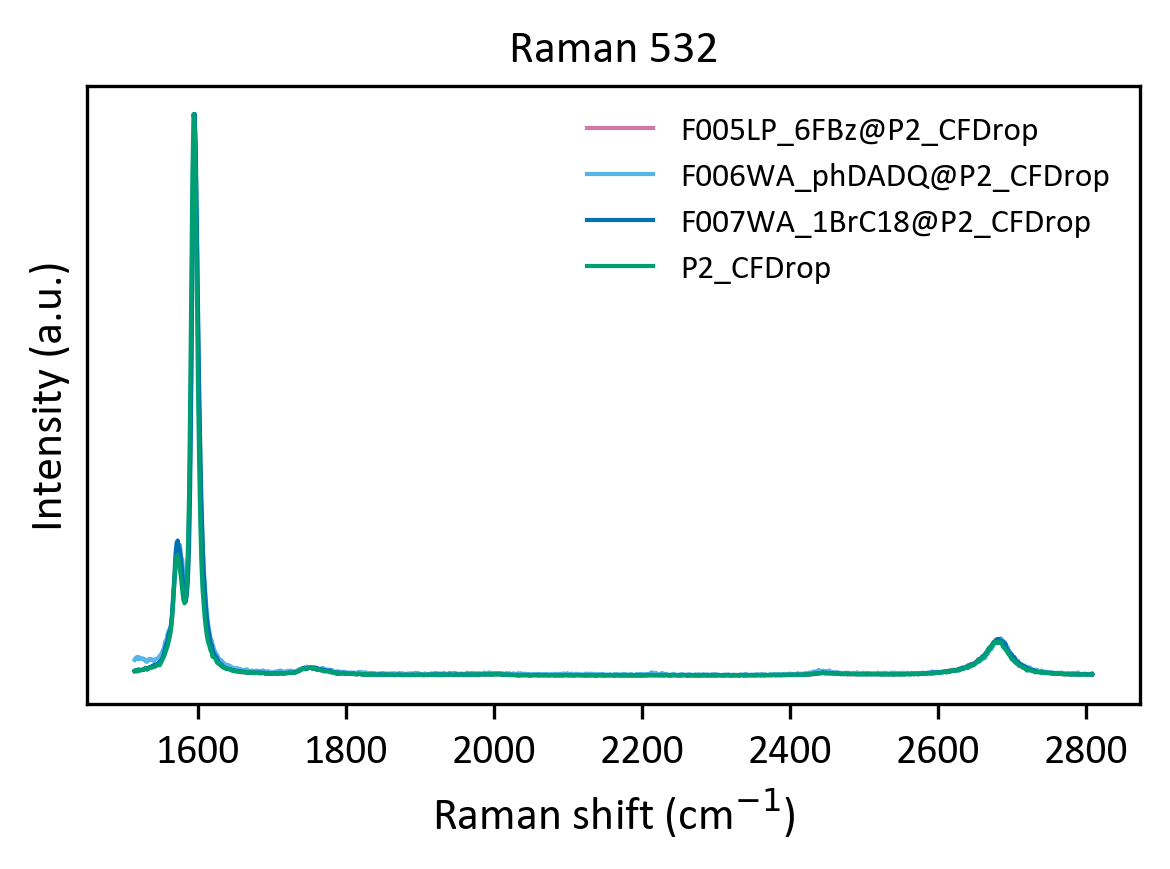

In [16]:
Data532nm1800gr260818B = [
    (Xpl_260818_F005LP_6FBz_in_P2_CFDrop_532_nm_1800gr_x50_LD_0_1pc_3_20_100_300_sc2150, 'F005LP_6FBz@P2_CFDrop', '#CC79A7', '-'),
    (Xpl_260818_F006WA_phDADQ_in_P2_CFDrop_532_nm_1800gr_x50_LD_0_1pc_3_20_100_300_sc2150, 'F006WA_phDADQ@P2_CFDrop', '#56B4E9', '-'),
    (Xpl_260818_F007WA_1BrC18_in_P2_CFDrop_532_nm_1800gr_x50_LD_0_1pc_3_20_100_300_sc2150, 'F007WA_1BrC18@P2_CFDrop', '#0072B2', '-'),
    (Xpl_260818_P2_CFDrop_532_nm_1800gr_x50_LD_0_1pc_3_20_100_300_sc2150, 'P2_CFDrop', '#009E73', '-'),
]

PlotRamanConfig(
    style=poster_style,
    config=Data532nm1800gr260818B, 
    spectra_dict=raman_spectra, 
    offset_step=0.0,
    #xmin=None, xmax=None, 
    #ymin=None, ymax=None,
    #norm_xmin=None, norm_xmax=None, norm_mode="M", 
    #subtract_min_first=True,
    #vlines=None, 
    hide_yticks=True, 
    legend_ncol=1,
    title="Raman 532", 
    save=True)

💾 Saved: H:\FUBerlin\PhD_CristianBorja\Results Overview\Push-pull (phDADQ)\Figures\Raman\Data532nm1800gr261114.svg


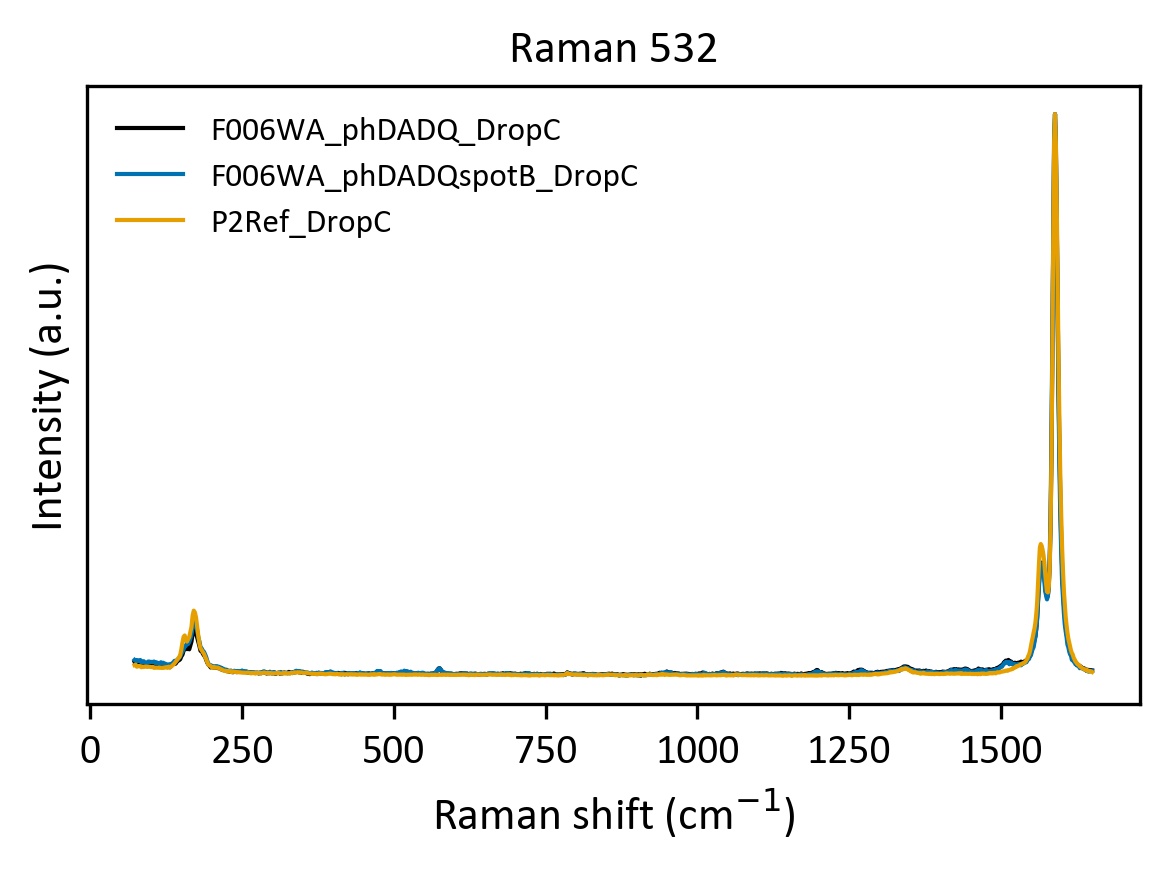

In [17]:
Data532nm1800gr261114 = [
    (Xpl_261114_F006WA_phDADQ_DropC_532_nm_1800gr_x50_LD_0_1pc_3_45_100_500_sc850, 'F006WA_phDADQ_DropC', '#000000', '-'),
    (Xpl_261114_F006WA_phDADQspotB_DropC_532_nm_1800gr_x50_LD_0_1pc_3_45_100_500_sc850, 'F006WA_phDADQspotB_DropC', '#0072B2', '-'),
    (Xpl_261114_P2Ref_DropC_532_nm_1800gr_x50_LD_0_1pc_3_45_100_500_sc850, 'P2Ref_DropC', '#E69F00', '-'),
]

PlotRamanConfig(
    style=poster_style,
    config=Data532nm1800gr261114, 
    spectra_dict=raman_spectra, 
    offset_step=0.0,
    #xmin=None, xmax=None, 
    #ymin=None, ymax=None,
    #norm_xmin=None, norm_xmax=None, norm_mode="M", 
    #subtract_min_first=True,
    #vlines=None, 
    hide_yticks=True, 
    legend_ncol=1,
    title="Raman 532", 
    save=True)

In [18]:
MakeConfig(raman_spectra, where="(F006 OR phDADQ OR P2) AND (532) AND (2400gr)")

# Found 4 spectra (where=(F006 OR phDADQ OR P2) AND (532) AND (2400gr))
config = [
    (Xpl_P2TS_RBM_532_nm_2400gr_x10_5_5_s_10pc, 'P2TS_RBM', '#000000', '-'),
    (Xpl_P2_TS_RBM___532_nm_2400gr_x10_2_120_s_1pc, 'P2_TS_RBM', '#0072B2', '-'),
    (Xpl_261114_F006WA_phDADQ_532_nm_2400gr_x50_1pc_3_90_50_100_sc550, 'F006WA_phDADQ', '#E69F00', '-'),
    (Xpl_261114_P2Ref_DropC_532_nm_2400gr_x50_1pc_3_90_50_100_sc550, 'P2Ref_DropC', '#009E73', '-'),
]


💾 Saved: H:\FUBerlin\PhD_CristianBorja\Results Overview\Push-pull (phDADQ)\Figures\Raman\Data532nm2400gr261114.svg


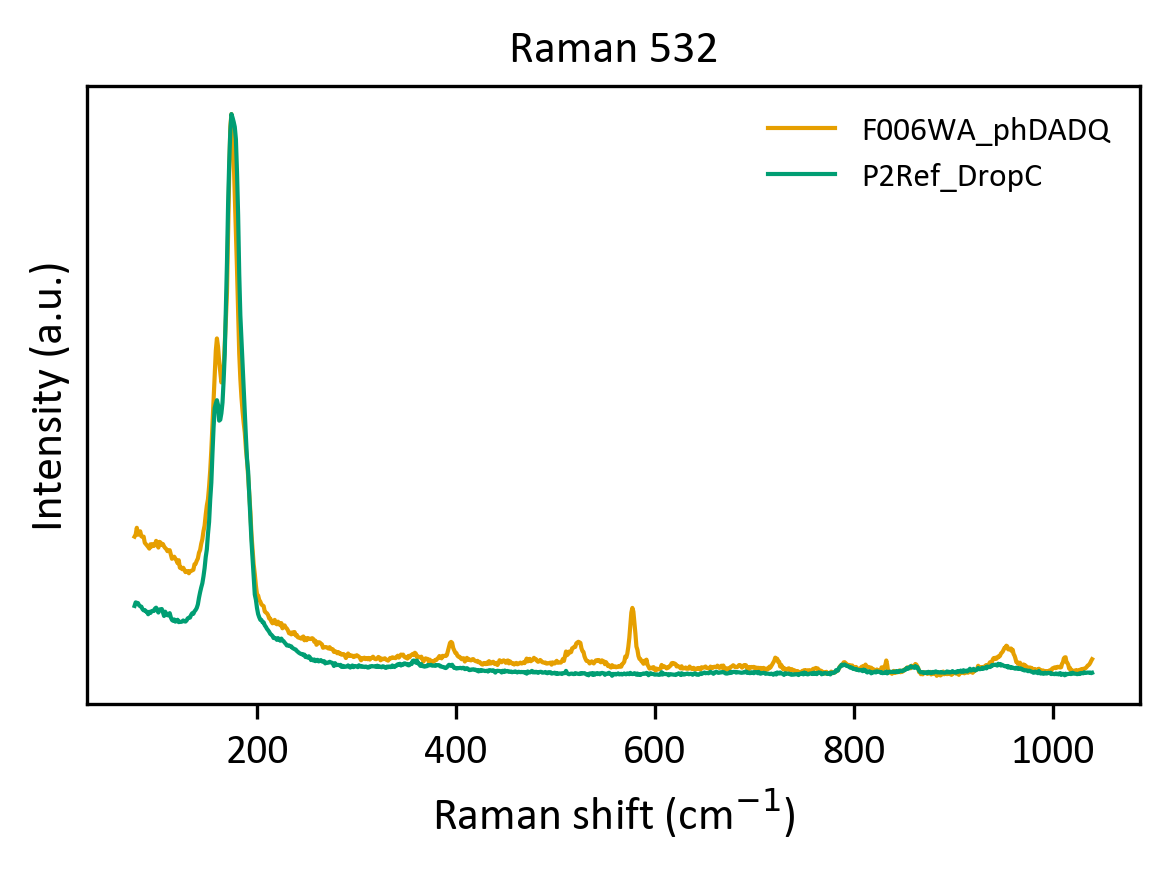

In [19]:
Data532nm2400gr261114 = [
    (Xpl_261114_F006WA_phDADQ_532_nm_2400gr_x50_1pc_3_90_50_100_sc550, 'F006WA_phDADQ', '#E69F00', '-'),
    (Xpl_261114_P2Ref_DropC_532_nm_2400gr_x50_1pc_3_90_50_100_sc550, 'P2Ref_DropC', '#009E73', '-'),
]

PlotRamanConfig(
    style=poster_style,
    config=Data532nm2400gr261114, 
    spectra_dict=raman_spectra, 
    offset_step=0.0,
    #xmin=None, xmax=None, 
    #ymin=None, ymax=None,
    #norm_xmin=None, norm_xmax=None, norm_mode="M", 
    #subtract_min_first=True,
    #vlines=None, 
    hide_yticks=True, 
    legend_ncol=1,
    title="Raman 532", 
    save=True)

## 638nm Data

In [32]:
MakeConfig(raman_spectra, where="(F006 OR phDADQ OR P2) AND (638nm) AND (600gr)")

# Found 19 spectra (where=(F006 OR phDADQ OR P2) AND (638nm) AND (600gr))
config = [
    (Xpl_260605_F005AP_6FBz_in_P2Sol_CF260528_638_nm_600gr_x10_1pc_3_60_50_100_sc1870, 'F005AP_6FBz@P2Sol_CF260528', '#000000', '-'),
    (Xpl_260605_F005LP_6FBz_in_P2Sol_CF260528_638_nm_600gr_x10_1pc_3_60_50_100_sc1870, 'F005LP_6FBz@P2Sol_CF260528', '#0072B2', '-'),
    (Xpl_260605_F006WA_phDADQ_in_P2Sol_CF260605_638_nm_600gr_x10_1pc_3_60_50_100_sc1870, 'F006WA_phDADQ@P2Sol_CF260605', '#E69F00', '-'),
    (Xpl_260605_P2_RefSol_NS_CF260529_638_nm_600gr_x10_1pc_3_60_50_100_sc1870, 'P2_RefSol_NS_CF260529', '#009E73', '-'),
    (Xpl_260605_P2_RefSol_TSR2_CF260224_638_nm_600gr_x10_1pc_3_60_50_100_sc1870, 'P2_RefSol_TSR2_CF260224', '#CC79A7', '-'),
    (Xpl_260818_F005LP_6FBz_in_P2_CFDrop_638_nm_600gr_x50_LD_0_1pc_3_20_100_300_sc1870, 'F005LP_6FBz@P2_CFDrop', '#D55E00', '-'),
    (Xpl_260818_F006WA_phDADQ_in_P2_CFDrop_638_nm_600gr_x50_LD_0_1pc_3_20_100_300_sc1870, 'F006WA_phDADQ@P2_CFDrop', '#56B4E9', '-'),

In [36]:
#%matplotlib inline
%matplotlib widget

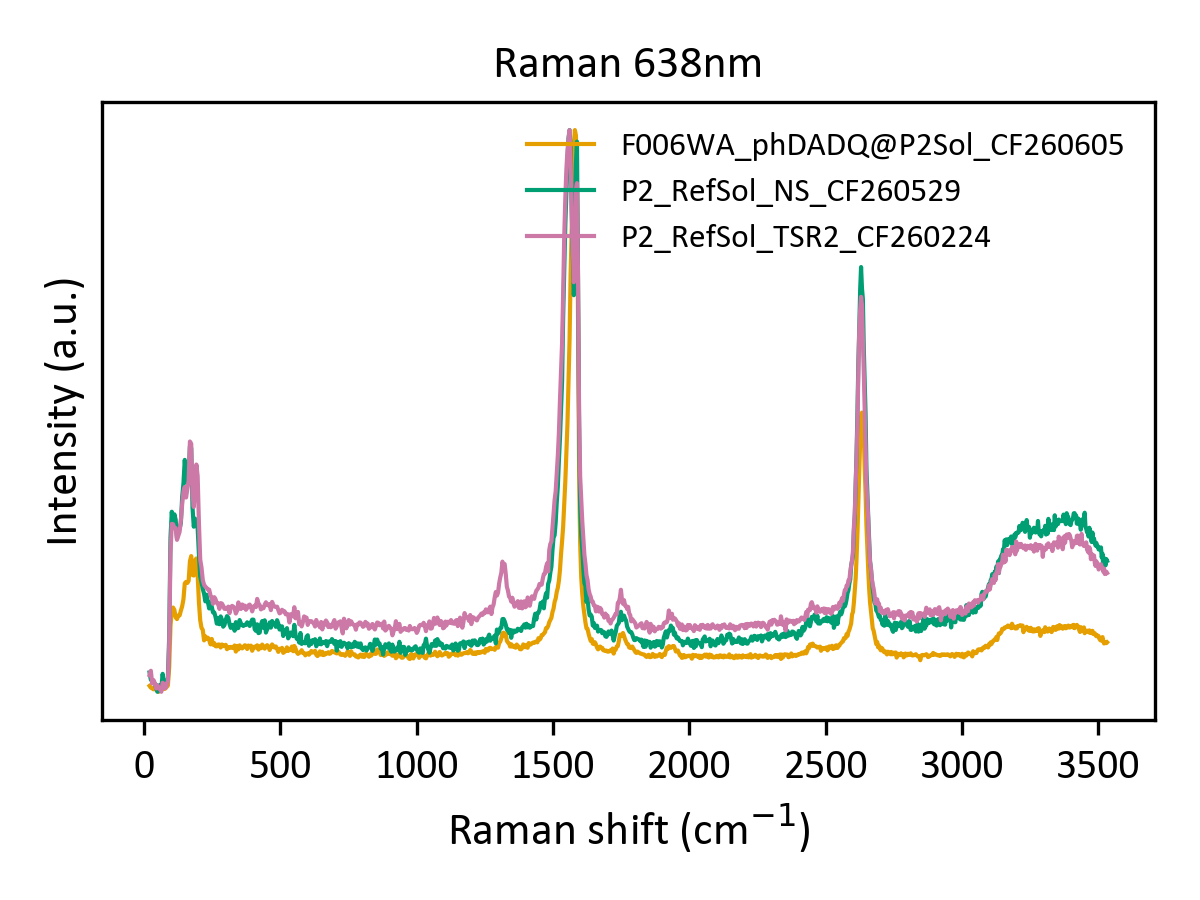

In [40]:
Data638nm600gr260605 = [
    (Xpl_260605_F006WA_phDADQ_in_P2Sol_CF260605_638_nm_600gr_x10_1pc_3_60_50_100_sc1870, 'F006WA_phDADQ@P2Sol_CF260605', '#E69F00', '-'),
    (Xpl_260605_P2_RefSol_NS_CF260529_638_nm_600gr_x10_1pc_3_60_50_100_sc1870, 'P2_RefSol_NS_CF260529', '#009E73', '-'),
    (Xpl_260605_P2_RefSol_TSR2_CF260224_638_nm_600gr_x10_1pc_3_60_50_100_sc1870, 'P2_RefSol_TSR2_CF260224', '#CC79A7', '-'),
    ]

PlotRamanConfig(
    style=poster_style,
    config=Data638nm600gr260605, 
    spectra_dict=raman_spectra, 
    offset_step=0.0,
    #xmin=None, xmax=None, 
    #ymin=None, ymax=None,
    #norm_xmin=None, norm_xmax=None, norm_mode="M", 
    #subtract_min_first=True,
    #vlines=None, 
    hide_yticks=True, 
    legend_ncol=1,
    title="Raman 638nm", 
    save=False)

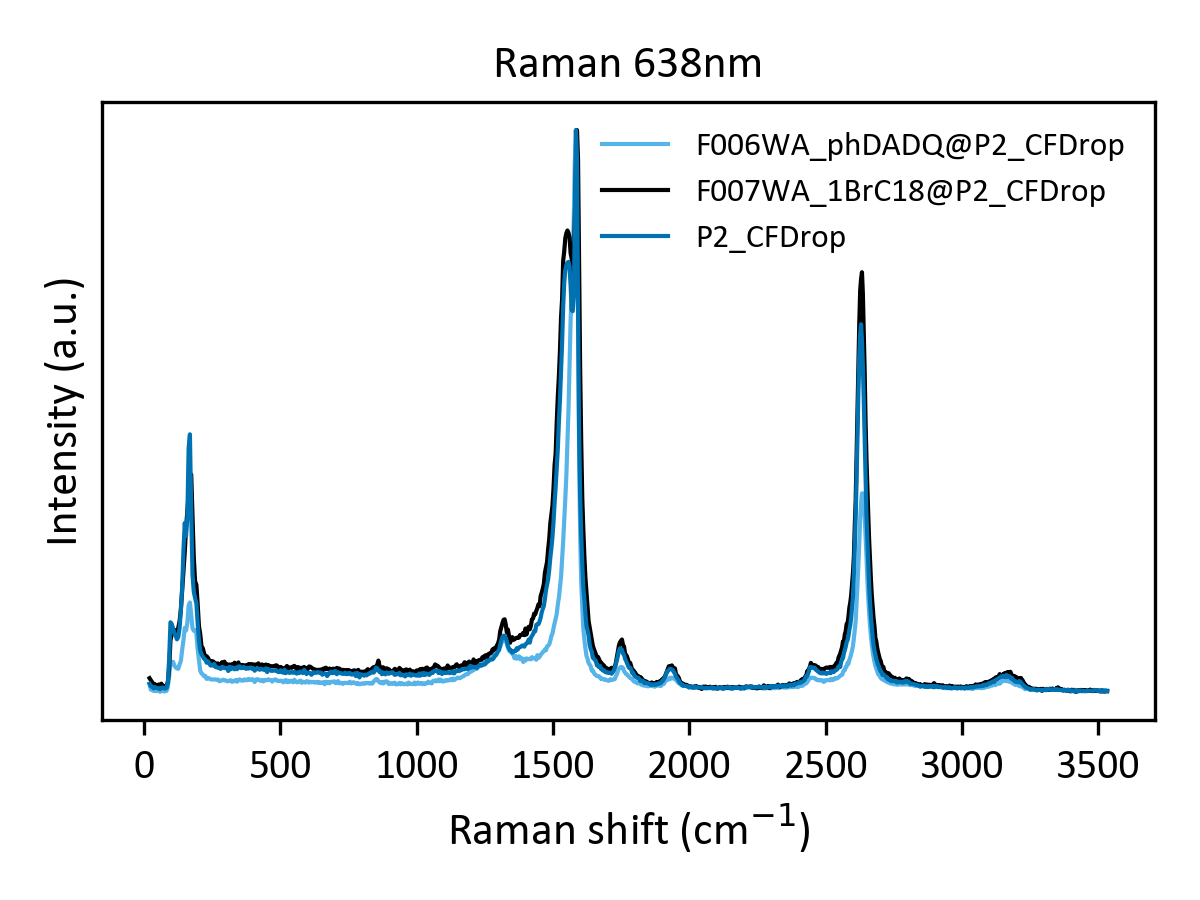

In [41]:
Data638nm600gr260818 = [
    (Xpl_260818_F006WA_phDADQ_in_P2_CFDrop_638_nm_600gr_x50_LD_0_1pc_3_20_100_300_sc1870, 'F006WA_phDADQ@P2_CFDrop', '#56B4E9', '-'),
    (Xpl_260818_F007WA_1BrC18_in_P2_CFDrop_638_nm_600gr_x50_LD_0_1pc_3_20_100_300_sc1870, 'F007WA_1BrC18@P2_CFDrop', '#000000', '-'),
    (Xpl_260818_P2_CFDrop_638_nm_600gr_x50_LD_0_1pc_3_20_100_300_sc1870, 'P2_CFDrop', '#0072B2', '-'),
    ]

PlotRamanConfig(
    style=poster_style,
    config=Data638nm600gr260818, 
    spectra_dict=raman_spectra, 
    offset_step=0.0,
    #xmin=None, xmax=None, 
    #ymin=None, ymax=None,
    #norm_xmin=None, norm_xmax=None, norm_mode="M", 
    #subtract_min_first=True,
    #vlines=None, 
    hide_yticks=True, 
    legend_ncol=1,
    title="Raman 638nm", 
    save=False)

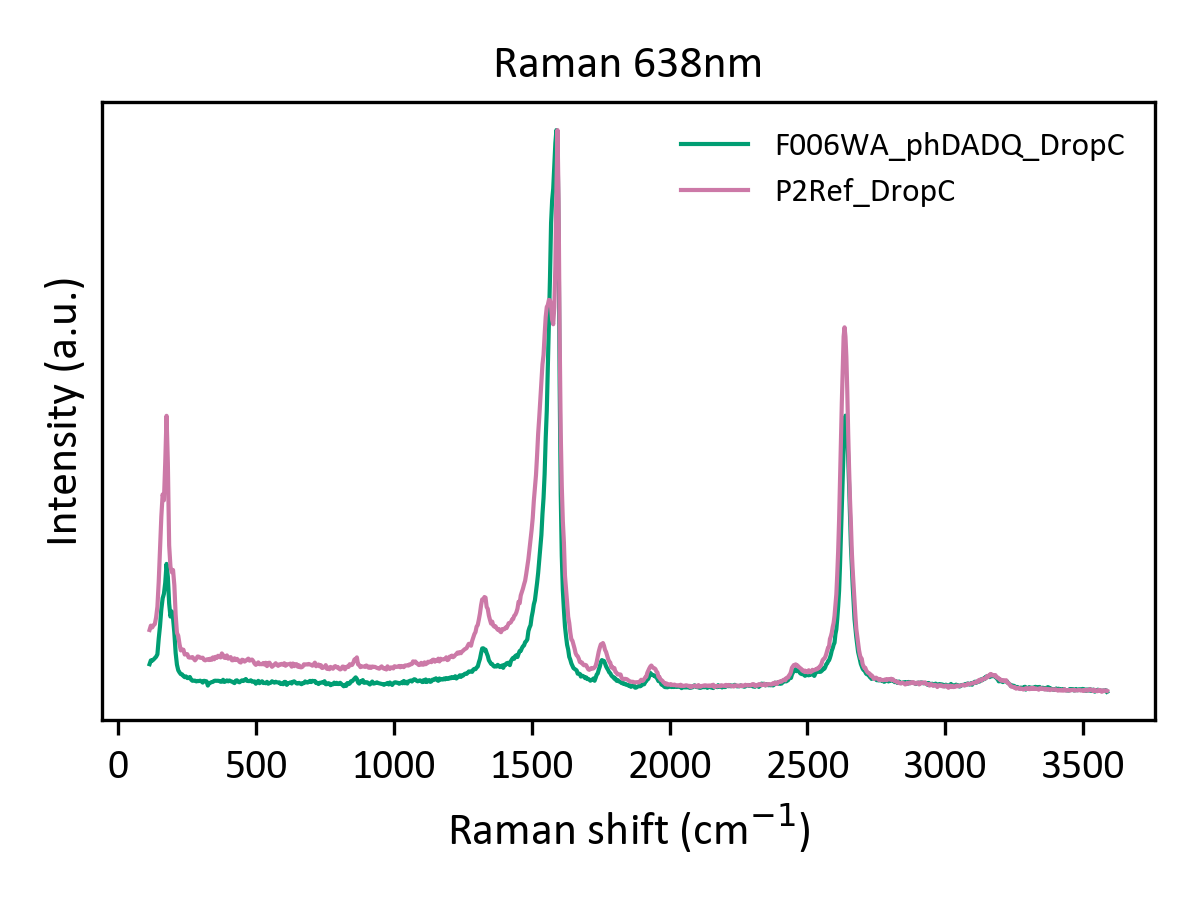

In [42]:
Data638nm600gr261114 = [   
    (Xpl_261114_F006WA_phDADQ_DropC_638_nm_600gr_x50_LD_0_1pc_3_30_100_500_sc1940, 'F006WA_phDADQ_DropC', '#009E73', '-'),
    (Xpl_261114_P2Ref_DropC_638_nm_600gr_x50_LD_0_1pc_3_30_100_500_sc1940, 'P2Ref_DropC', '#CC79A7', '-'),
    ]

PlotRamanConfig(
    style=poster_style,
    config=Data638nm600gr261114, 
    spectra_dict=raman_spectra, 
    offset_step=0.0,
    #xmin=None, xmax=None, 
    #ymin=None, ymax=None,
    #norm_xmin=None, norm_xmax=None, norm_mode="M", 
    #subtract_min_first=True,
    #vlines=None, 
    hide_yticks=True, 
    legend_ncol=1,
    title="Raman 638nm", 
    save=False)